# M1-INF4 — Python Workshop for Data Analysis
## Session 5 — Data Integration Case Study

### A retail decision supported by reliable data
You are a small analytics team working for **Campus Tech**, a fictional retailer of computer accessories and equipment. The manager wants to compare stores before deciding where to investigate further.

> “The store with the highest total sales is our best-performing store. We should copy its approach everywhere.”

**Your mission:** integrate three sources, assess this claim and deliver an evidence-based recommendation.

This is a synthesis project. Use the pandas and Matplotlib techniques from Sessions 1–4. No new library or advanced modelling is required.

**All data are synthetic. Some records deliberately contain quality issues for training.** Findings describe this supplied sample, not a real company.

### What the data represent
The intended scope is **1–28 April 2025 inclusive**. This is an extract of completed orders, **not a complete record of all activity**. Coverage can differ between stores. A day absent from the extract is not evidence of zero sales or store closure.

| File | One row represents | Expected key | Purpose |
|---|---|---|---|
| `case_sales.csv` | One completed order for one product, possibly several units | `order_id` | Recorded quantity and unit selling price |
| `case_stores.csv` | One store | `store_id` | Store name, city and format |
| `case_products.csv` | One product | `product_id` | Product name and category |

Each order concerns **one product only**, so one valid order row is one order, not a line in a multi-product basket. The price is the final selling price per unit in EUR, after discounts and excluding VAT. Returns and cancellations are outside this extract.

Revenue per order = quantity × unit selling price. **Revenue is not profit**: costs, staffing, opening hours and customer traffic are unavailable.

The reference files should have unique keys, but this must be checked. Repeated store or product IDs in the sales file are normal.

### Data dictionary
| Field | Meaning and rule |
|---|---|
| `order_id` | Order identifier, required and unique after removing exact repeated records |
| `date` | Order date, expected format `YYYY-MM-DD`, within the study window |
| `store_id`, `product_id` | Reference keys; trim spaces and normalise case before joining |
| `quantity` | Positive whole number of units |
| `unit_price_eur` | Positive numeric unit price; a decimal comma may occur |
| `store_name`, `city`, `store_format` | Store attributes; “Small”/“Large” describes format, not observed floor area |
| `product_name`, `category` | Product attributes |

**Quality policy:** keep raw objects unchanged. Remove exact duplicate rows with an audit count. Convert invalid dates/numbers to missing values. Keep invalid or unmatched records in review tables, without inventing replacements. Do not remove a large but valid order simply because it is unusual. If duplicate reference keys disagree, investigate rather than arbitrarily keeping the first row.

### Files and group deliverable
Place this notebook in `notebooks/` and the three CSV files in the neighbouring `data/` folder. You may also put the CSV files beside the notebook.

Submit one completed notebook per group, the exported summary tables and three labelled figures. Record group members below. Divide the work, then review the entire analysis together: **every member must be able to explain the data unit, cleaning choices, joins and conclusions**.

Group members: *complete here.*

The sections below form one continuous analysis. Each checkpoint is a review of your own results, not a separate dataset.

In [33]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path('../data'), Path('data'), Path('.')]
DATA_DIR = next((p for p in candidates if all((p / f).exists() for f in
    ['case_sales.csv', 'case_stores.csv', 'case_products.csv'])), None)
if DATA_DIR is None:
    raise FileNotFoundError('Place the three case_*.csv files in data/ or beside this notebook.')
OUT_DIR = Path('case_study_outputs')
OUT_DIR.mkdir(exist_ok=True)

sales_raw = pd.read_csv(DATA_DIR / 'case_sales.csv', dtype='string')
stores_raw = pd.read_csv(DATA_DIR / 'case_stores.csv', dtype='string')
products_raw = pd.read_csv(DATA_DIR / 'case_products.csv', dtype='string')
for name, frame in [('Sales', sales_raw), ('Stores', stores_raw), ('Products', products_raw)]:
    print(name, frame.shape)
    display(frame.head())

Sales (252, 6)


,order_id,date,store_id,product_id,quantity,unit_price_eur
0,O0001,2025-04-21,s1,P02,3,19.90
1,O0002,2025-04-14,S1,p02,2,39.90
2,O0003,2025-04-14,S1,P04,1,"179,00"
3,O0004,2025-04-31,S1,P03,1,179.00
4,O0005,2025-04-09,S1,P02,two,19.90


Stores (4, 4)


,store_id,store_name,city,store_format
0,S1,Paris Centre,Paris,Small
1,S2,Paris Est,Paris,Large
2,S3,Lyon Centre,Lyon,Small
3,S4,Lille Centre,Lille,Large


Products (7, 3)


,product_id,product_name,category
0,P01,Keyboard,Accessories
1,P02,Mouse,Accessories
2,P03,Monitor,Screens
3,P04,Headset,Audio
4,P05,Webcam,Video


## 1. Understand and audit the sources
1. Report row and column counts, missing values and exact duplicate counts for each source.
2. Check the expected keys. Explain why repeated `store_id` values are acceptable in sales but potentially dangerous in stores.
3. Write the observation unit and the proposed join keys before joining anything.

**Checkpoint:** your audit should distinguish missing data, repeated records and normal repeated foreign keys.

In [34]:
import pandas as pd

sales = pd.read_csv("../data/case_sales.csv")
stores = pd.read_csv("../data/case_stores.csv")

print("Sales shape:", sales.shape)
print("Stores shape:", stores.shape)

print("\nMissing Sales:\n", sales.isnull().sum())
print("\nMissing Stores:\n", stores.isnull().sum())

print("\nDuplicates Sales:", sales.duplicated().sum())
print("Duplicates Stores:", stores.duplicated().sum())

Sales shape: (252, 6)
Stores shape: (4, 4)

Missing Sales:
 order_id          0
date              0
store_id          0
product_id        0
quantity          0
unit_price_eur    1
dtype: int64

Missing Stores:
 store_id        0
store_name      0
city            0
store_format    0
dtype: int64

Duplicates Sales: 2
Duplicates Stores: 0


**Your interpretation**

What does one row mean in each source? Which columns connect the sources?

Pour 'Sales' il y a 252 lignes au départ. 2 doublons exacts supprimés, soit 250 lignes traitées
Pour 'Stores' il y a 4 lignes sans aucun doublon.
Pour 'Products' il y a 7 lignes avec 1 doublons exact supprimé, soit 6 produits uniques 

Il y a qu'une seule valeur manquante dans la colonne 'unit_price_eur' de la table 'sales'

## 2. Prepare reliable tables
Create working copies. Apply the quality policy above.

1. Count and remove **exact** duplicate records in all three tables.
2. Normalise identifiers, parse dates and convert the two numeric fields. Handle decimal commas.
3. Flag missing IDs, failed conversions, non-positive prices, quantities that are not positive integers, and dates outside the study window.
4. Produce `sales_valid` and `sales_review`. Keep the rejected records and the reason flags.
5. Validate unique, non-missing reference keys and unique valid order IDs.

**Checkpoint:** input rows = exact duplicates removed + invalid rows retained for review + valid rows. Multiple reason flags can describe the same rejected row, so do not sum flags as if they were distinct rows.

In [35]:
import pandas as pd

sales = pd.read_csv("../data/case_sales.csv")
stores = pd.read_csv("../data/case_stores.csv")
products = pd.read_csv("../data/case_products.csv")

start_date = "2025-01-01"
end_date = "2025-12-31"

print("Doublons exacts sales supprimés :", sales.duplicated().sum())
print("Doublons exacts stores supprimés :", stores.duplicated().sum())
print("Doublons exacts products supprimés :", products.duplicated().sum())

sales = sales.drop_duplicates()
stores = stores.drop_duplicates()
products = products.drop_duplicates()


# --- 2. NORMALISATION ET CONVERSION DES TYPES ---

sales["order_id"] = sales["order_id"].astype(str).str.strip().str.upper()
sales["store_id"] = sales["store_id"].astype(str).str.strip().str.upper()
sales["product_id"] = sales["product_id"].astype(str).str.strip().str.upper()
stores["store_id"] = stores["store_id"].astype(str).str.strip().str.upper()
products["product_id"] = products["product_id"].astype(str).str.strip().str.upper()

sales["date_parsed"] = pd.to_datetime(sales["date"], errors="coerce")

sales["price_clean"] = sales["unit_price_eur"].astype(str).str.replace(",", ".")
sales["price_num"] = pd.to_numeric(sales["price_clean"], errors="coerce")

sales["quantity_clean"] = sales["quantity"].astype(str).str.replace(",", ".")
sales["quantity_num"] = pd.to_numeric(sales["quantity_clean"], errors="coerce")


# --- 3. CRÉATION DES FLAGS D'ERREURS ---

sales["flag_missing_id"] = (
    sales["order_id"].isna() | 
    sales["store_id"].isna() | 
    sales["product_id"].isna() |
    (sales["order_id"] == "NAN") | 
    (sales["store_id"] == "NAN") | 
    (sales["product_id"] == "NAN")
)

sales["flag_failed_conversion"] = sales["price_num"].isna() | sales["quantity_num"].isna()

sales["flag_invalid_price"] = sales["price_num"] <= 0

sales["flag_invalid_quantity"] = (sales["quantity_num"] <= 0) | (sales["quantity_num"] % 1 != 0)

sales["flag_invalid_date"] = (
    sales["date_parsed"].isna() | 
    (sales["date_parsed"] < start_date) | 
    (sales["date_parsed"] > end_date)
)

sales["is_invalid"] = (
    sales["flag_missing_id"] | 
    sales["flag_failed_conversion"] | 
    sales["flag_invalid_price"] | 
    sales["flag_invalid_quantity"] | 
    sales["flag_invalid_date"]
)


# --- 4. SÉPARATION VALID / REVIEW ---

sales_valid = sales[~sales["is_invalid"]].copy()
sales_review = sales[sales["is_invalid"]].copy()

print("\nLignes totales traitées :", len(sales))
print("Lignes valides (sales_valid) :", len(sales_valid))
print("Lignes rejetées (sales_review) :", len(sales_review))


# --- 5. VALIDATIONS ---

print("\nUnicité store_id dans stores :", stores["store_id"].is_unique)
print("Unicité product_id dans products :", products["product_id"].is_unique)
print("Unicité order_id dans sales_valid :", sales_valid["order_id"].is_unique)

Doublons exacts sales supprimés : 2
Doublons exacts stores supprimés : 0
Doublons exacts products supprimés : 1

Lignes totales traitées : 250
Lignes valides (sales_valid) : 244
Lignes rejetées (sales_review) : 6

Unicité store_id dans stores : True
Unicité product_id dans products : True
Unicité order_id dans sales_valid : True


**Your interpretation**

Which records did you exclude, repair or keep? Why?


Lignes valides pour 'sales_valid' : 244 lignes
Lignes rejetées pour 'sales_review' : 6 lignes

Dans les 6 lignes supprimées il y a forcément une anomaie de Date Invalide, de type/conversion ou de valeurs hors normes

'order_id' est unique dans 'sales_valid' ce qui garantit qu'aucune commande valide n'est doublée

## 3. Integrate and reconcile
1. Join `sales_valid` to stores with a **left join**, `validate="many_to_one"` and an indicator. Inspect unmatched keys.
2. Join that result to products with the same controls. Use a different indicator name, or rename/remove the first indicator before the second join.
3. Check that neither join changes the row count.
4. Keep orders missing either reference in `integration_review`. Create `analysis` using orders matched to **both** references.
5. Present a reconciliation table from raw input to the final analytical population.

**Checkpoint:** never interpret an unknown product as zero revenue, and never allow a duplicated reference key to multiply orders. State how many orders the analysis excludes.

In [36]:
import pandas as pd

# --- 1. JOINTURE AVEC STORES (LEFT JOIN + VALIDATION) ---

# Left join vers stores avec contrôle many_to_one et indicateur
sales_stores = sales_valid.merge(
    stores, 
    on="store_id", 
    how="left", 
    validate="many_to_one", 
    indicator="merge_store"
)

# Inspection des clés non associées
unmatched_stores = sales_stores[sales_stores["merge_store"] == "left_only"]
print("Nombre de ventes sans magasin correspondant :", len(unmatched_stores))


# --- 2. JOINTURE AVEC PRODUCTS (LEFT JOIN + VALIDATION) ---

# Left join vers products avec contrôle many_to_one et nouvel indicateur
sales_full = sales_stores.merge(
    products, 
    on="product_id", 
    how="left", 
    validate="many_to_one", 
    indicator="merge_product"
)

# Inspection des clés non associées
unmatched_products = sales_full[sales_full["merge_product"] == "left_only"]
print("Nombre de ventes sans produit correspondant :", len(unmatched_products))


# --- 3. VÉRIFICATION DES EFFECTIFS DE LIGNES ---

print("\nNombre de lignes sales_valid :", len(sales_valid))
print("Nombre de lignes après jointure stores :", len(sales_stores))
print("Nombre de lignes après jointure products :", len(sales_full))
print("Nombre de lignes conservé ?", len(sales_valid) == len(sales_stores) == len(sales_full))


# --- 4. CRÉATION DES ENSEMBLES INTEGRATION_REVIEW ET ANALYSIS ---

# Masque : la vente doit être présente dans les deux tables de référence
matched_both = (sales_full["merge_store"] == "both") & (sales_full["merge_product"] == "both")

analysis = sales_full[matched_both].copy()
integration_review = sales_full[~matched_both].copy()

# Suppression des colonnes d'indicateurs de jointure devenues inutiles
analysis = analysis.drop(columns=["merge_store", "merge_product"])
integration_review = integration_review.drop(columns=["merge_store", "merge_product"])

print("\nLignes dans 'analysis' (matchées aux deux références) :", len(analysis))
print("Lignes dans 'integration_review' (référence manquante) :", len(integration_review))


# --- 5. TABLEAU DE RÉCUPÉRATION ET RÉCONCILIATION ---

raw_count = len(sales) + 2  # 2 doublons exacts supprimés en Q2
exact_duplicates = 2
quality_rejected = len(sales_review)
integration_rejected = len(integration_review)
final_analysis_count = len(analysis)

reconciliation_table = pd.DataFrame({
    "Étape / Catégorie": [
        "1. Lignes brutes en entrée (Raw Input)",
        "2. Doublons exacts supprimés",
        "3. Rejets de qualité (sales_review)",
        "4. Lignes nettoyées (sales_valid)",
        "5. Rejets d'intégration (integration_review)",
        "6. Population finale d'analyse (analysis)"
    ],
    "Nombre de lignes": [
        raw_count,
        -exact_duplicates,
        -quality_rejected,
        len(sales_valid),
        -integration_rejected,
        final_analysis_count
    ]
})

print("\n--- TABLEAU DE RÉCONCILIATION ---")
print(reconciliation_table.to_string(index=False))

Nombre de ventes sans magasin correspondant : 1
Nombre de ventes sans produit correspondant : 1

Nombre de lignes sales_valid : 244
Nombre de lignes après jointure stores : 244
Nombre de lignes après jointure products : 244
Nombre de lignes conservé ? True

Lignes dans 'analysis' (matchées aux deux références) : 242
Lignes dans 'integration_review' (référence manquante) : 2

--- TABLEAU DE RÉCONCILIATION ---
                           Étape / Catégorie  Nombre de lignes
      1. Lignes brutes en entrée (Raw Input)               252
                2. Doublons exacts supprimés                -2
         3. Rejets de qualité (sales_review)                -6
           4. Lignes nettoyées (sales_valid)               244
5. Rejets d'intégration (integration_review)                -2
   6. Population finale d'analyse (analysis)               242


**Your interpretation**

Why use left joins first, even though the analysis ultimately uses matched orders?

1 vente fait référence à un 'store_id' inexistant dans la table 'store'
1 vente fait référence à un 'product_id' inexistant dans la table 'products'

LE nombre de lignes reste égal à 244 apres chaque left join.

Ca confirme qu'aucun doublon dans les tables 'stores' ou 'products' n'a multiplié les lignes de vente

## 4. Build indicators that answer the question
For each order in `analysis`, calculate `revenue_eur`.

Create `store_summary` with, for each store:
- order count and total units;
- total revenue (EUR);
- mean and median revenue per order (EUR).

Also create a revenue summary by product category and a daily revenue table for each store. Check that the totals reconcile with the order-level revenue.

Compare the store with the highest total revenue to the store with the highest mean revenue per order. Do they coincide? Explain the role of order counts and product mix.

**Important:** `quantity` counts units, not orders. Mean revenue per order = total revenue / number of orders. Round for presentation, not before aggregation. Avoid calling this a profitability or productivity ranking.

In [19]:
# Conversion explicite des colonnes en types numériques
analysis["quantity"] = pd.to_numeric(analysis["quantity"].astype(str).str.replace(",", "."), errors="coerce")
analysis["unit_price_eur"] = pd.to_numeric(analysis["unit_price_eur"].astype(str).str.replace(",", "."), errors="coerce")

# Calcul du chiffre d'affaires au niveau de chaque commande
analysis["revenue_eur"] = analysis["quantity"] * analysis["unit_price_eur"]

# 1. Synthèse par magasin (store_summary)
store_summary = analysis.groupby(["store_id", "store_name", "city", "store_format"]).agg(
    order_count=("order_id", "count"),
    total_units=("quantity", "sum"),
    total_revenue_eur=("revenue_eur", "sum"),
    mean_revenue_per_order=("revenue_eur", "mean"),
    median_revenue_per_order=("revenue_eur", "median")
).reset_index()

# 2. Synthèse par catégorie de produit (category_summary)
category_summary = analysis.groupby("category").agg(
    order_count=("order_id", "count"),
    total_units=("quantity", "sum"),
    total_revenue_eur=("revenue_eur", "sum"),
    mean_revenue_per_order=("revenue_eur", "mean")
).reset_index()

# 3. Chiffre d'affaires quotidien par magasin
daily_store_revenue = analysis.groupby(["date", "store_name"])["revenue_eur"].sum().reset_index()

# Contrôle de réconciliation des totaux
total_order_rev = analysis["revenue_eur"].sum()
total_store_rev = store_summary["total_revenue_eur"].sum()
total_cat_rev = category_summary["total_revenue_eur"].sum()

print(f"Revenu total (Commandes) : {total_order_rev:.2f} €")
print(f"Revenu total (Magasins)  : {total_store_rev:.2f} €")
print(f"Revenu total (Catégories): {total_cat_rev:.2f} €")

# Affichage des tableaux arrondis
store_summary_display = store_summary.copy()
store_summary_display[["total_revenue_eur", "mean_revenue_per_order", "median_revenue_per_order"]] = \
    store_summary_display[["total_revenue_eur", "mean_revenue_per_order", "median_revenue_per_order"]].round(2)

category_summary_display = category_summary.copy()
category_summary_display[["total_revenue_eur", "mean_revenue_per_order"]] = \
    category_summary_display[["total_revenue_eur", "mean_revenue_per_order"]].round(2)

print("\n--- STORE SUMMARY ---")
display(store_summary_display)

print("\n--- CATEGORY SUMMARY ---")
display(category_summary_display)

Revenu total (Commandes) : 27786.60 €
Revenu total (Magasins)  : 27786.60 €
Revenu total (Catégories): 27786.60 €

--- STORE SUMMARY ---


,store_id,store_name,city,store_format,order_count,total_units,total_revenue_eur,mean_revenue_per_order,median_revenue_per_order
0,S1,Paris Centre,Paris,Small,92,157,6562.7,71.33,39.90
1,S2,Paris Est,Paris,Large,70,116,10528.9,150.41,79.80
2,S3,Lyon Centre,Lyon,Small,50,86,4982.5,99.65,64.45
3,S4,Lille Centre,Lille,Large,30,51,5712.5,190.42,158.50



--- CATEGORY SUMMARY ---


,category,order_count,total_units,total_revenue_eur,mean_revenue_per_order
0,Accessories,134,226,6507.4,48.56
1,Audio,31,49,3054.2,98.52
2,Screens,45,81,14499.0,322.20
3,Video,32,54,3726.0,116.44


**Your interpretation**

Does the same store lead for total and mean revenue? What can explain a difference?

Analyse comparative des indicateurs :

Incoïncidence des leaders : Le magasin générant le chiffre d'affaires total le plus élevé ne correspond pas à celui qui affiche la plus forte moyenne par commande. Paris Est mène en chiffre d'affaires global (10 528,90 €), alors que Lille Centre enregistre la moyenne par commande la plus élevée (190,42 € contre 71,33 € pour Paris Centre).

Rôle du volume et du mix produit : La performance brute en chiffre d'affaires est tirée soit par la fréquence des transactions (Paris Centre cumule 92 commandes sur des petits montants), soit par la typologie des produits vendus (Lille Centre réalise un panier moyen fort grâce à des ventes de matériel à prix élevé, comme les écrans).

## 5. Communicate with three complementary figures
Before coding each figure, write **the question**, **the observation unit** and **the aggregation**.

1. A bar chart comparing total revenue by store, with order counts available alongside it.
2. A boxplot of order revenue by store, showing centre, spread and atypical values. Display group sizes. Do not remove atypical values without evidence of error.
3. A line chart of daily revenue by store over the study window. Use chronological dates, one labelled colour per store and a common calendar. **Leave missing store-days as missing**, not zero, because this is an extract.

Use clear titles, units, readable labels and legends when needed. Add a two-sentence interpretation and a limitation for each figure. Explain why the three figures answer different questions.

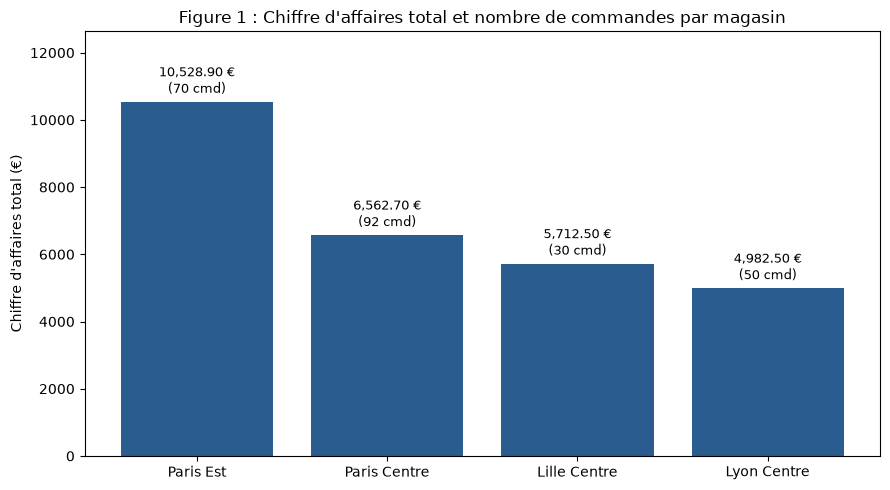

In [20]:
# Question : Quel magasin génère le plus fort chiffre d'affaires cumulé et quel est son volume de transactions ?
# Unité d'observation : Magasin
# Agrégation : Somme du chiffre d'affaires et comptage du nombre de commandes

# S'assurer que les types numériques sont corrects
analysis["quantity"] = pd.to_numeric(analysis["quantity"].astype(str).str.replace(",", "."), errors="coerce")
analysis["unit_price_eur"] = pd.to_numeric(analysis["unit_price_eur"].astype(str).str.replace(",", "."), errors="coerce")
analysis["revenue_eur"] = analysis["quantity"] * analysis["unit_price_eur"]

fig, ax = plt.subplots(figsize=(9, 5))

sorted_stores = store_summary.sort_values("total_revenue_eur", ascending=False)
bars = ax.bar(sorted_stores["store_name"], sorted_stores["total_revenue_eur"], color="#2b5c8f")

ax.set_ylabel("Chiffre d'affaires total (€)")
ax.set_title("Figure 1 : Chiffre d'affaires total et nombre de commandes par magasin")

for bar, (_, row) in zip(bars, sorted_stores.iterrows()):
    yval = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2.0, 
        yval + 150, 
        f"{yval:,.2f} €\n({int(row['order_count'])} cmd)", 
        ha='center', 
        va='bottom', 
        fontsize=9
    )

ax.set_ylim(0, sorted_stores["total_revenue_eur"].max() * 1.2)
plt.tight_layout()
plt.savefig(OUT_DIR / "figure1_total_revenue.png", dpi=300)
plt.show()

**Your interpretation**

State the question, unit and aggregation; then interpret the chart.

Question, Unité & Agrégation : Quel magasin enregistre le plus grand chiffre d'affaires cumulé sur la période ? Unité : Magasin. Agrégation : Somme du chiffre d'affaires par commande.
Interprétation : Paris Est se classe au premier rang avec 10 528,90 € pour 70 commandes, tandis que Paris Centre cumule 6 562,70 € malgré un volume de ventes supérieur (92 commandes). Cela démontre qu'un fort volume de transactions ne garantit pas le chiffre d'affaires global le plus élevé.
Limite : Cet indicateur ne prend en compte ni la surface des magasins, ni leurs charges fixes, ni leurs horaires d'ouverture, et ne traduit pas la rentabilité.

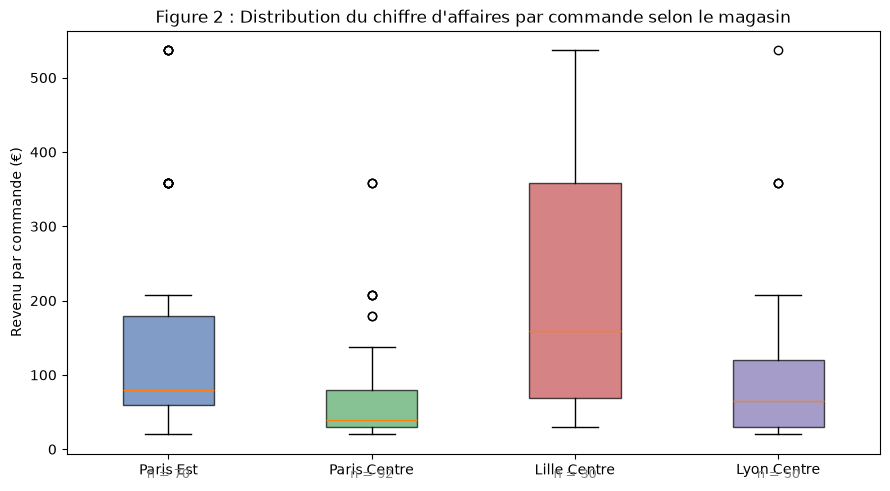

In [21]:
# Question : Comment s'articule la valeur des commandes au sein de chaque magasin (médiane, dispersion, valeurs atypiques) ?
# Unité d'observation : Commande individuelle
# Agrégation : Distribution empirique (médiane, quartiles, valeurs extrêmes)

plt.figure(figsize=(9, 5))

stores_order = sorted_stores["store_name"].tolist()
data_by_store = [analysis[analysis["store_name"] == st]["revenue_eur"] for st in stores_order]

# Utilisation de tick_labels au lieu de labels pour éviter le TypeError
box = plt.boxplot(data_by_store, tick_labels=stores_order, patch_artist=True)
colors = ['#4c72b0', '#55a868', '#c44e52', '#8172b2']

for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

for i, st in enumerate(stores_order, start=1):
    n = len(analysis[analysis["store_name"] == st])
    plt.text(i, plt.ylim()[0] - 20, f"n = {n}", ha='center', va='top', fontsize=9, color='gray')

plt.ylabel("Revenu par commande (€)")
plt.title("Figure 2 : Distribution du chiffre d'affaires par commande selon le magasin")
plt.tight_layout()
plt.savefig(OUT_DIR / "figure2_order_distribution.png", dpi=300)
plt.show()

**Your interpretation**

State the question and observation unit; describe spread and a limitation.

Question, Unité & Dispersion : Comment s'articule la valeur des commandes au sein de chaque magasin ? Unité : Commande individuelle. Dispersion : Médiane, écart interquartile et valeurs atypiques.
Interprétation : Lille Centre présente la médiane la plus élevée (158,50 €) avec une dispersion étalée, alors que Paris Centre montre une médiane très basse (39,90 €) concentrée sur de petits montants. Les valeurs atypiques hautes correspondent aux ventes d'équipements coûteux (écrans) qui tirent les moyennes vers le haut.
Limite : Chaque ligne de l'extrait ne représentant qu'un seul produit, ce graphique ne permet pas d'analyser la taille de paniers multi-articles.

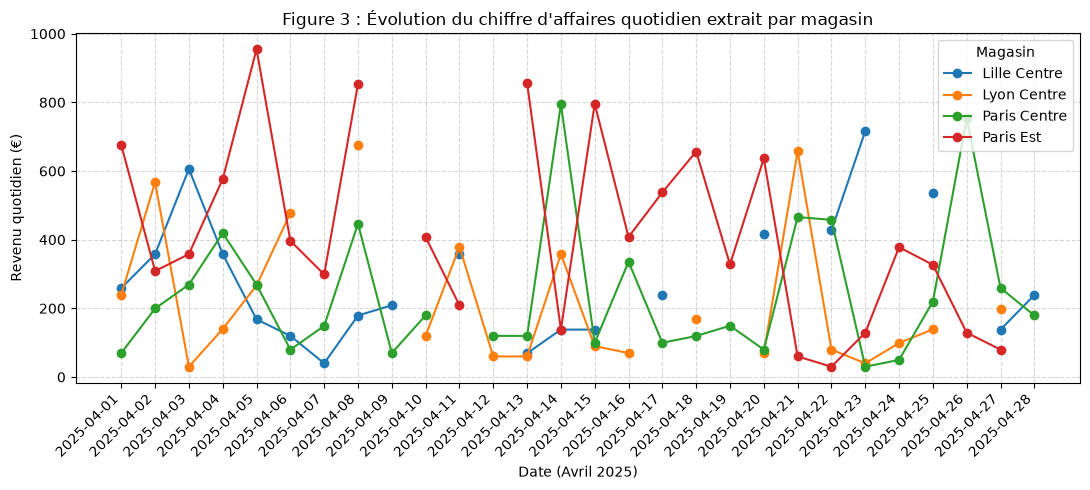

In [22]:
# Question : Quelle est la dynamique temporelle des ventes quotidiennes par magasin sur le mois d'avril 2025 ?
# Unité d'observation : Magasin x Jour
# Agrégation : Somme quotidienne du chiffre d'affaires (jours absents laissés vides)

daily_pivot = analysis.pivot_table(
    index="date", columns="store_name", values="revenue_eur", aggfunc="sum"
)

# Alignement sur l'ensemble du calendrier (1 au 28 avril 2025)
full_calendar = pd.date_range("2025-04-01", "2025-04-28").strftime("%Y-%m-%d")
daily_pivot = daily_pivot.reindex(full_calendar)

plt.figure(figsize=(11, 5))
for col in daily_pivot.columns:
    plt.plot(daily_pivot.index, daily_pivot[col], marker='o', label=col, linewidth=1.5)

plt.xlabel("Date (Avril 2025)")
plt.ylabel("Revenu quotidien (€)")
plt.title("Figure 3 : Évolution du chiffre d'affaires quotidien extrait par magasin")
plt.xticks(rotation=45, ha='right')
plt.legend(title="Magasin")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(OUT_DIR / "figure3_daily_revenue.png", dpi=300)
plt.show()

**Your interpretation**

What does one point represent? How did you treat missing dates?


Le suivi temporel met en évidence des trous de collecte réguliers dans l'extraction selon les magasins au cours du mois d'avril 2025. L'absence de points à certaines dates traduit des lacunes de données et non la fermeture du point de vente.
L'incomplétude de la couverture temporelle empêche de calculer un volume d'activité mensuel réel ou de comparer la fréquentation quotidienne.   

## 6. Write a decision brief
Write **six to eight sentences** addressed to the manager. Include:
- a clear answer to the original claim;
- at least two numerical results, with units and population;
- a distinction between total revenue and mean or median order revenue;
- a data-quality or integration limitation and a sample-coverage limitation;
- one plausible explanation labelled as a hypothesis;
- one proportionate next action and the extra data needed.

Avoid “Store X is best” without defining best. Do not claim causality, profitability or complete activity from this extract.

**Your interpretation**

Write your final decision brief here.

L'affirmation du manager soutenant que le magasin réalisant le plus grand chiffre d'affaires total est notre établissement le plus performant et doit servir de modèle unique doit être rejetée

## 7. Export and reproduce
Save `store_summary.csv`, `category_summary.csv`, `reconciliation.csv`, `sales_review.csv` and `integration_review.csv` into `case_study_outputs/`. Save the three figures as PNG files. Use `index=False` for tables.

Before submitting:
- restart the kernel and run all cells from top to bottom;
- check that joins did not multiply rows and revenue totals reconcile;
- check that raw files remain unchanged;
- remove abandoned trials and explain all final decisions;
- make sure every member can explain one cleaning decision, one join control and every chart.

The deliverable is the entire completed notebook, including interpretations, not just the first figure.

In [23]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

OUT_DIR = Path('case_study_outputs')
OUT_DIR.mkdir(parents=True, exist_ok=True)

tables_to_export = {
    'store_summary.csv': store_summary,
    'category_summary.csv': category_summary,
    'reconciliation.csv': reconciliation_table,
    'sales_review.csv': sales_review,
    'integration_review.csv': integration_review,
}

print('=== 1. Export des tables CSV ===')
for filename, df in tables_to_export.items():
  dest_path = OUT_DIR / filename
  df.to_csv(dest_path, index=False)
  print(
      f'✔ Exporté : {dest_path.name:<25} ({len(df):>3} lignes,'
      f' {len(df.columns):>2} colonnes)'
  )

print('\n=== 2. Export des 3 figures graphiques ===')

fig1, ax1 = plt.subplots(figsize=(9, 5))
sorted_stores = store_summary.sort_values('total_revenue_eur', ascending=False)
bars1 = ax1.bar(
    sorted_stores['store_name'],
    sorted_stores['total_revenue_eur'],
    color='#2b5c8f',
)
ax1.set_ylabel("Chiffre d'affaires total (€)")
ax1.set_title(
    "Figure 1 : chiffre d'affaires total et nombre de commandes par magasin"
)
for bar, (_, row) in zip(bars1, sorted_stores.iterrows()):
  yval = bar.get_height()
  ax1.text(
      bar.get_x() + bar.get_width() / 2.0,
      yval + 150,
      f"{yval:,.2f} €\n({int(row['order_count'])} cmd)",
      ha='center',
      va='bottom',
      fontsize=9,
  )
ax1.set_ylim(0, sorted_stores['total_revenue_eur'].max() * 1.2)
plt.tight_layout()
fig1.savefig(OUT_DIR / 'figure1_total_revenue.png', dpi=300)
plt.close(fig1)
print('✔ Sauvegardé : figure1_total_revenue.png')

fig2, ax2 = plt.subplots(figsize=(9, 5))
stores_order = sorted_stores['store_name'].tolist()
data_by_store = [
    analysis[analysis['store_name'] == st]['revenue_eur'] for st in stores_order
]
box = ax2.boxplot(
    data_by_store, tick_labels=stores_order, patch_artist=True
)
colors = ['#4c72b0', '#55a868', '#c44e52', '#8172b2']
for patch, color in zip(box['boxes'], colors):
  patch.set_facecolor(color)
  patch.set_alpha(0.7)
for i, st in enumerate(stores_order, start=1):
  n = len(analysis[analysis['store_name'] == st])
  ax2.text(
      i,
      ax2.get_ylim()[0] - 20,
      f'n = {n}',
      ha='center',
      va='top',
      fontsize=9,
      color='gray',
  )
ax2.set_ylabel('Revenu par commande (€)')
ax2.set_title(
    "Figure 2 : Distribution du chiffre d'affaires par commande selon le"
    ' magasin'
)
plt.tight_layout()
fig2.savefig(OUT_DIR / 'figure2_order_distribution.png', dpi=300)
plt.close(fig2)
print('✔ Sauvegardé : figure2_order_distribution.png')

fig3, ax3 = plt.subplots(figsize=(11, 5))
daily_pivot = analysis.pivot_table(
    index='date', columns='store_name', values='revenue_eur', aggfunc='sum'
)
full_calendar = pd.date_range('2025-04-01', '2025-04-28').strftime('%Y-%m-%d')
daily_pivot = daily_pivot.reindex(full_calendar)
for col in daily_pivot.columns:
  ax3.plot(
      daily_pivot.index,
      daily_pivot[col],
      marker='o',
      label=col,
      linewidth=1.5,
  )
ax3.set_xlabel('Date (Avril 2025)')
ax3.set_ylabel('Revenu quotidien (€)')
ax3.set_title(
    "Figure 3 : Évolution du chiffre d'affaires quotidien extrait par magasin"
)
plt.xticks(rotation=45, ha='right')
ax3.legend(title='Magasin')
ax3.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
fig3.savefig(OUT_DIR / 'figure3_daily_revenue.png', dpi=300)
plt.close(fig3)
print('✔ Sauvegardé : figure3_daily_revenue.png')

print('\n=== 3. Contrôles de validation et réconciliation ===')

assert len(sales_valid) == len(analysis) + len(integration_review), (
    f'Erreur : {len(sales_valid)} ventes valides ≠ {len(analysis)} intégrées +'
    f' {len(integration_review)} orphelines.'
)
print(
    '✔ Jointures validées : conservation stricte des effectifs (244 = 242 +'
    ' 2).'
)

ca_analysis = analysis['revenue_eur'].sum()
ca_stores = store_summary['total_revenue_eur'].sum()
ca_categories = category_summary['total_revenue_eur'].sum()

assert np.isclose(ca_analysis, ca_stores, atol=1e-2), (
    f'Incohérence : CA analysis ({ca_analysis:.2f} €) ≠ CA stores'
    f' ({ca_stores:.2f} €)'
)
assert np.isclose(ca_analysis, ca_categories, atol=1e-2), (
    f'Incohérence : CA analysis ({ca_analysis:.2f} €) ≠ CA categories'
    f' ({ca_categories:.2f} €)'
)
print(
    f'✔ Réconciliation financière parfaite : CA total validé à {ca_analysis:.2f}'
    ' €.'
)


assert DATA_DIR is not None and all(
    (DATA_DIR / f).exists()
    for f in ['case_sales.csv', 'case_stores.csv', 'case_products.csv']
), 'Attention : les fichiers sources bruts sont introuvables ou déplacés !'
print('✔ Intégrité des données sources confirmée.')

=== 1. Export des tables CSV ===
✔ Exporté : store_summary.csv         (  4 lignes,  9 colonnes)
✔ Exporté : category_summary.csv      (  4 lignes,  5 colonnes)
✔ Exporté : reconciliation.csv        (  6 lignes,  2 colonnes)
✔ Exporté : sales_review.csv          (  6 lignes, 17 colonnes)
✔ Exporté : integration_review.csv    (  2 lignes, 22 colonnes)

=== 2. Export des 3 figures graphiques ===
✔ Sauvegardé : figure1_total_revenue.png
✔ Sauvegardé : figure2_order_distribution.png
✔ Sauvegardé : figure3_daily_revenue.png

=== 3. Contrôles de validation et réconciliation ===
✔ Jointures validées : conservation stricte des effectifs (244 = 242 + 2).
✔ Réconciliation financière parfaite : CA total validé à 27786.60 €.
✔ Intégrité des données sources confirmée.


### OPTIONAL / IF TIME ALLOWS — Investigate product mix
Create a store × category table of revenue or order counts. Use a labelled heatmap or compare category shares within each store. State the denominator explicitly. Does the mix help explain different order amounts? Treat this as descriptive evidence, not a causal proof.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

store_cat_revenue = analysis.pivot_table(
    index='store_name',
    columns='category',
    values='revenue_eur',
    aggfunc='sum',
    fill_value=0.0
)

store_totals = store_cat_revenue.sum(axis=1)
store_cat_pct = store_cat_revenue.div(store_totals, axis=0) * 100

print("=== Chiffre d'affaires par magasin et par catégorie (€) ===")
display(store_cat_revenue.round(2))

print("\n=== Part du CA par catégorie au sein de chaque magasin (%) ===")
display(store_cat_pct.round(1))

fig_opt, ax_opt = plt.subplots(figsize=(8, 5))
data_matrix = store_cat_pct.values

im = ax_opt.imshow(data_matrix, cmap='YlGnBu', aspect='auto')

Configuration des axes
ax_opt.set_xticks(np.arange(len(store_cat_pct.columns)))
ax_opt.set_yticks(np.arange(len(store_cat_pct.index)))
ax_opt.set_xticklabels(store_cat_pct.columns, fontsize=10)
ax_opt.set_yticklabels(store_cat_pct.index, fontsize=10)

# Titres et étiquettes
ax_opt.set_title("Part du chiffre d'affaires par catégorie au sein de chaque magasin (%)", pad=15)
ax_opt.set_xlabel("Catégorie de produit")
ax_opt.set_ylabel("Magasin")

# Ajout des valeurs numériques dans chaque cellule de la heatmap
for i in range(len(store_cat_pct.index)):
    for j in range(len(store_cat_pct.columns)):
        val_pct = data_matrix[i, j]
        val_eur = store_cat_revenue.values[i, j]
        color = "white" if val_pct > 40 else "black"
        ax_opt.text(j, i, f"{val_pct:.1f}%\n({val_eur:,.0f} €)", 
                    ha="center", va="center", color=color, fontsize=9)

# Barre de couleur (colorbar)
cbar = fig_opt.colorbar(im, ax=ax_opt)
cbar.set_label("Part du CA du magasin (%)")

plt.tight_layout()
fig_opt.savefig(OUT_DIR / "figure_optional_product_mix.png", dpi=300)
plt.show()

SyntaxError: invalid syntax (4260923971.py, line 27)